# SCM203405 — Sistemas de Comunicação
## Laboratório: Modulação e Demodulação BPSK

**Curso:** Superior em Eletrônica Industrial – IFSC, Florianópolis

---
## 0. Preparação do ambiente

Execute a célula abaixo para importar as bibliotecas necessárias.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
import hashlib

plt.rcParams['figure.figsize'] = (10, 4)


---
## 1. Parâmetros individualizados

Preencha sua matrícula abaixo. A função `parametros_individualizados` deriva,
de forma determinística, um conjunto de parâmetros **único para você**: a
frequência da portadora $f_c$, a duração de bit $T_b$ e a sequência de
**10 bits** que você vai modular. Rode a célula e **não altere os valores
gerados** — todo o restante do laboratório deve usar exatamente esses
parâmetros.

In [ ]:
MATRICULA = "89"

def parametros_individualizados(matricula: str):
    """Gera parametros determinísticos e únicos por matrícula."""
    h = hashlib.sha256(matricula.encode()).hexdigest()
    seed = int(h[:8], 16)
    rng = np.random.default_rng(seed)

    Tb = 1e-3
    k = 2 + seed % 5
    fracao = [0.0, 0.25, 0.5][(seed // 5) % 3]
    fc = (k + fracao) / Tb
    bits = rng.integers(0, 2, size=10)

    return {
        "seed": seed,
        "Tb": Tb,
        "fc": fc,
        "ciclos_por_bit": fc * Tb,
        "bits": bits,
    }

params = parametros_individualizados(MATRICULA)
for k, v in params.items():
    print(f"{k}: {v}")


> **Atenção:** guarde o valor de `ciclos_por_bit` ($f_c T_b$) impresso
> acima — ele indica se cada intervalo de bit contém um número inteiro de
> ciclos da portadora. Isso será relevante na Seção 6.

---
## 2. Modulador BPSK

Implemente um código que module a sequência binária de **10 bits** da
Seção 1 no formato BPSK, segundo o diagrama de blocos abaixo, **usando
exatamente os parâmetros da Seção 1** (`fc`, `Tb`, `bits`).

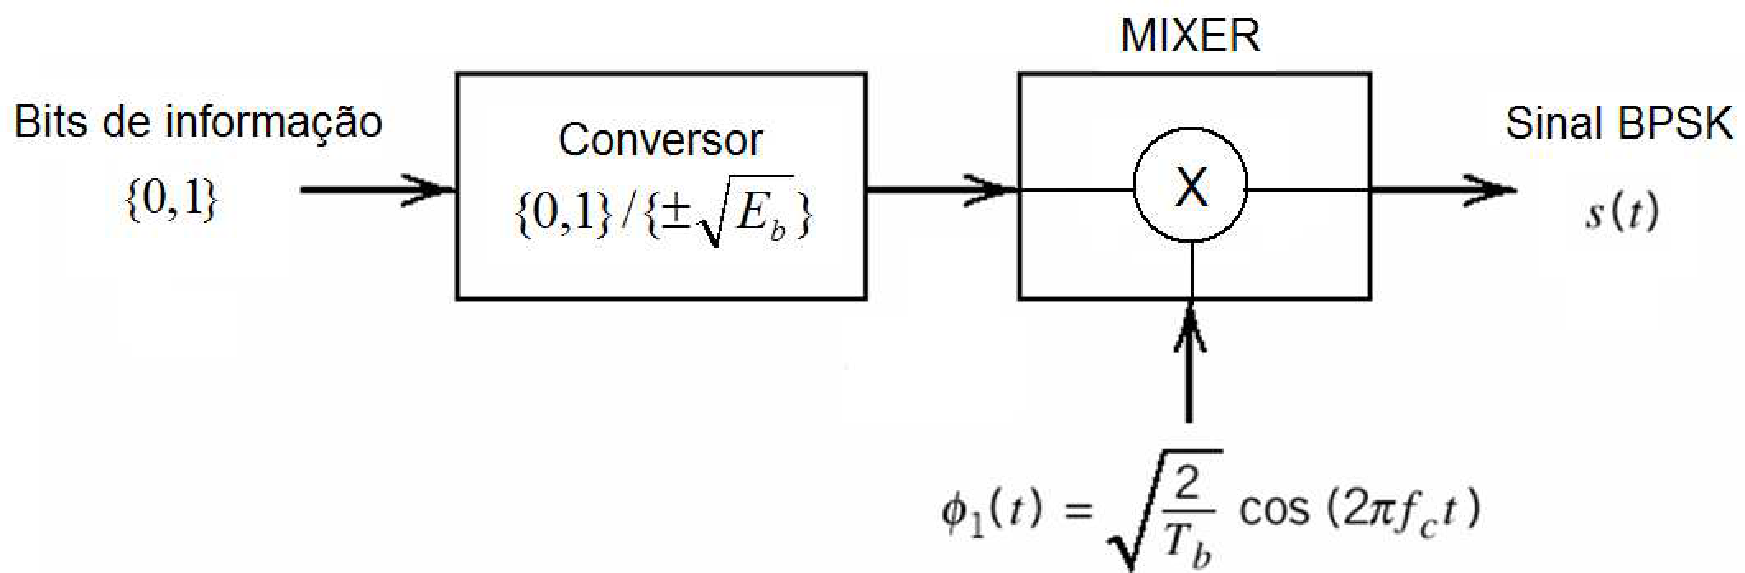

**Observações sobre os blocos:**

a) O bloco **Conversor** é um codificador de linha **NRZ polar** com
   amplitudes $\pm\sqrt{E_b}$: bit 1 → $+\sqrt{E_b}$; bit 0 → $-\sqrt{E_b}$.

b) O bloco **Mixer** é apenas a multiplicação da saída do conversor pela
   função-base (portadora utilizada):
$$\phi_1(t) = \sqrt{\frac{2}{T_b}}\cos(2\pi f_c t)$$

   de modo que o sinal transmitido é
$$s(t) = \pm\sqrt{E_b}\,\phi_1(t) = \pm\sqrt{\frac{2E_b}{T_b}}\cos(2\pi f_c t),
  \qquad 0 \le t < T_b$$

   Note que $-\cos(\cdot) = \cos(\cdot + \pi)$: os dois símbolos diferem
   apenas por uma inversão de fase de 180°.

**O que fazer:**
1. Complete a função `modula_bpsk` abaixo (os `TODO`s).
2. Gere o sinal $s(t)$ para os 10 bits da Seção 1.
3. Plote a saída do conversor NRZ polar e $s(t)$ no domínio do tempo
   (sugestão: dois subplots alinhados no mesmo eixo de tempo, para que as
   inversões de fase fiquem visíveis nas transições de bit).
4. Plote o espectro de amplitude de $s(t)$ (via FFT) no domínio da
   frequência, identificando $f_c$ no gráfico.

In [ ]:
Eb = 1.0
fs = 200_000

def modula_bpsk(bits, fc, Tb, Eb, fs):
    """
    Retorna (t, nrz, s) onde:
      t   : vetor de tempo
      nrz : saída do bloco Conversor (NRZ polar, +-sqrt(Eb))
      s   : sinal BPSK modulado, s(t)
    """
    n_amostras_por_bit = int(round(Tb * fs))
    t = np.arange(len(bits) * n_amostras_por_bit, dtype=float) / fs
    nrz = np.empty_like(t)
    s = np.empty_like(t)
    phi1 = np.sqrt(2.0 / Tb) * np.cos(2.0 * np.pi * fc * t)

    for i, bit in enumerate(bits):
        inicio = i * n_amostras_por_bit
        fim = (i + 1) * n_amostras_por_bit
        nivel = np.sqrt(Eb) if bit == 1 else -np.sqrt(Eb)
        nrz[inicio:fim] = nivel
        s[inicio:fim] = nivel * phi1[inicio:fim]

    return t, nrz, s

t, nrz, s = modula_bpsk(params["bits"], params["fc"], params["Tb"], Eb, fs)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t[:min(len(t), 1000)], nrz[:min(len(nrz), 1000)], color="tab:blue", lw=1.5)
axes[0].set_title("NRZ polar")
axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)

axes[1].plot(t[:min(len(t), 1000)], s[:min(len(s), 1000)], color="tab:orange", lw=1.5)
axes[1].set_title("Sinal BPSK no domínio do tempo")
axes[1].set_xlabel("Tempo (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

fft_freq = np.fft.rfftfreq(len(s), d=1.0 / fs)
fft_mag = np.abs(np.fft.rfft(s))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(fft_freq, fft_mag, color="tab:green", lw=1.5)
ax.axvline(params["fc"], color="tab:red", ls="--", lw=1.5, label=f"f_c = {params['fc']:.3f} Hz")
ax.set_xlim(0, max(params["fc"], 1000) * 2)
ax.set_xlabel("Frequência (Hz)")
ax.set_ylabel("Magnitude")
ax.set_title("Espectro de amplitude do sinal BPSK")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


---
## 3. Demodulador BPSK (receptor por correlação)

Implemente um código que demodule o sinal BPSK gerado na Seção 2 (ainda
**sem ruído**), segundo o diagrama abaixo.

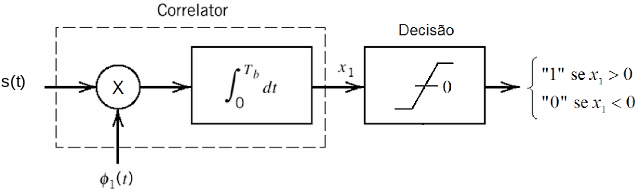

**Observações sobre os blocos:**

a) O bloco **Correlator** multiplica o sinal modulado pela **mesma
   função-base** $\phi_1(t)$ usada na modulação e faz a integral do
   resultado a cada intervalo de bit $T_b$:
$$x_1 = \int_{(i-1)T_b}^{iT_b} s(t)\,\phi_1(t)\,dt$$

b) O bloco **Decisão** verifica a polaridade de $x_1$: se $x_1 > 0$, bit
   **1** identificado; caso contrário ($x_1 < 0$), bit **0** reconhecido.

**O que fazer:**
1. Complete `demodula_bpsk`. Use o **mesmo vetor de tempo** `t` da
   modulação para gerar $\phi_1(t)$ no receptor (isto é, receptor
   perfeitamente sincronizado em fase com o transmissor).
2. Aplique-a ao sinal da Seção 2.
3. Imprima os valores de $x_1$ para cada bit e verifique se estão próximos
   do valor teórico esperado ($\pm\sqrt{E_b}$).
4. Mostre a sequência de bits original e a sequência demodulada (sinal
   após o bloco de Decisão) — em gráfico (ex.: `plt.step`, um subplot para
   cada) e em texto — e confirme que são idênticas (canal ainda ideal).

In [ ]:
def demodula_bpsk(t, s, fc, Tb, fs):
    """
    Retorna (bits_rx, x1):
      bits_rx : array de bits demodulados (saída do bloco Decisão)
      x1      : array com a saída do Correlator para cada bit
    """
    n_amostras_por_bit = int(round(Tb * fs))
    n_bits = len(s) // n_amostras_por_bit

    phi1 = np.sqrt(2.0 / Tb) * np.cos(2.0 * np.pi * fc * t)

    x1 = np.zeros(n_bits)
    bits_rx = np.zeros(n_bits, dtype=int)
    for i in range(n_bits):
        ini, fim = i * n_amostras_por_bit, (i + 1) * n_amostras_por_bit
        segmento = s[ini:fim]
        referencia = phi1[ini:fim]
        x1[i] = np.sum(segmento * referencia) / fs
        bits_rx[i] = 1 if x1[i] > 0 else 0

    return bits_rx, x1

bits_rx, x1 = demodula_bpsk(t, s, params["fc"], params["Tb"], fs)

print("x1 por bit:      ", np.round(x1, 4))
print("Bits originais:  ", params["bits"])
print("Bits demodulados:", bits_rx)
print("Identicos?", np.array_equal(params["bits"], bits_rx))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].step(np.arange(len(params["bits"])), params["bits"], where="mid", label="Original")
axes[0].set_title("Sequência original")
axes[0].set_ylabel("Bit")
axes[0].set_ylim(-0.1, 1.1)
axes[0].grid(alpha=0.3)

axes[1].step(np.arange(len(bits_rx)), bits_rx, where="mid", label="Demodulada", color="tab:orange")
axes[1].set_title("Sequência demodulada")
axes[1].set_xlabel("Índice do bit")
axes[1].set_ylabel("Bit")
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()


---
## 4. Canal com ruído (AWGN) e curva de BER

Um receptor que só funciona sem ruído não diz muito sobre um sistema de
comunicação real. Nesta seção você vai:

1. Usar o canal AWGN fornecido, que adiciona ruído gaussiano branco a
   $s(t)$ para um dado $E_b/N_0$.
2. Gerar uma sequência **longa** de bits (não apenas 10 — use pelo menos
   $10^4$ bits) com os mesmos `fc` e `Tb` da Seção 1.
3. Para uma faixa de $E_b/N_0$ (por exemplo, de 0 a 10 dB, em passos de 1
   ou 2 dB), simular transmissão + canal + recepção e calcular a BER
   (taxa de erro de bit) simulada.
4. Plotar a BER simulada (eixo y em escala log) versus $E_b/N_0$ (dB),
   **sobrepondo a curva teórica** da BPSK coerente:
$$P_e = Q\!\left(\sqrt{\frac{2E_b}{N_0}}\right)
      = \frac{1}{2}\,\mathrm{erfc}\!\left(\sqrt{\frac{E_b}{N_0}}\right), \qquad
  Q(x) = \frac{1}{2}\,\mathrm{erfc}\!\left(\frac{x}{\sqrt{2}}\right)$$
5. (Opcional, recomendado) Para um valor de $E_b/N_0$ baixo (ex.: 0 dB),
   plote o histograma dos valores de $x_1$ recebidos — o que você observa
   em torno de $\pm\sqrt{E_b}$?

**Antes de rodar a simulação:** calcule à mão (ou em uma célula separada,
sem usar a LLM para o cálculo em si) o valor teórico de $P_e$ para pelo
menos dois pontos de $E_b/N_0$ da sua faixa, e anote o resultado em uma
célula de markdown — isso será conferido depois.

**Cálculo teórico manual de $P_e$ (preencher antes da simulação):**

| $E_b/N_0$ (dB) | $E_b/N_0$ (linear) | $P_e$ calculado |
|---|---|---|
| | | |
| | | |

In [ ]:
def canal_awgn(s, EbN0_dB, Eb, Tb, fs):
    """Adiciona ruído gaussiano branco a s, para a relação Eb/N0 em dB."""
    EbN0 = 10 ** (EbN0_dB / 10)
    N0 = Eb / EbN0
    var_ruido = N0 * fs / 2
    ruido = np.random.normal(0, np.sqrt(var_ruido), size=len(s))
    return s + ruido


def calcula_ber(n_bits, EbN0_dB, fc, Tb, Eb, fs, rng):
    bits = rng.integers(0, 2, size=n_bits)
    t, nrz, s = modula_bpsk(bits, fc, Tb, Eb, fs)
    s_ruidoso = canal_awgn(s, EbN0_dB, Eb, Tb, fs)
    bits_rx, x1 = demodula_bpsk(t, s_ruidoso, fc, Tb, fs)
    n_erros = np.sum(bits != bits_rx)
    return n_erros / n_bits

n_bits = 10_000
EbN0_dB_range = np.arange(0, 11, 1)

rng = np.random.default_rng(params["seed"])
ber_simulada = [calcula_ber(n_bits, eb_db, params["fc"], params["Tb"], Eb, fs, rng) for eb_db in EbN0_dB_range]
ber_teorica = 0.5 * erfc(np.sqrt(10 ** (np.array(EbN0_dB_range) / 10.0)))

fig, ax = plt.subplots(figsize=(9, 6))
ax.semilogy(EbN0_dB_range, ber_simulada, "o-", color="tab:blue", label="Simulada")
ax.semilogy(EbN0_dB_range, ber_teorica, "s--", color="tab:red", label="Teórica")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("BER")
ax.set_title("BER simulada e teórica para BPSK coerente")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


---
## 5. Ocupação espectral

Usando o sinal $s(t)$ **sem ruído** da Seção 2 (se quiser uma estimativa
mais suave do espectro, gere uma sequência mais longa de bits aleatórios
com os mesmos `fc` e `Tb`):

1. Estime a largura de banda ocupada pelo sinal BPSK (por exemplo, banda
   que contém 99% da energia do sinal, e/ou a largura entre os primeiros
   nulos do lóbulo principal).
2. Compare o valor obtido com o valor teórico da largura entre nulos do
   lóbulo principal da BPSK, $B = 2/T_b$ (centrada em $f_c$).


In [ ]:
# Cálculo aproximado de largura de banda ocupada pela energia do sinal
spec = np.abs(np.fft.rfft(s)) ** 2
freqs = np.fft.rfftfreq(len(s), d=1.0 / fs)
energia_total = spec.sum()
energia_acumulada = np.cumsum(spec)
idx = np.where(energia_acumulada >= 0.99 * energia_total)[0]
if len(idx) > 0:
    largura_banda_99 = 2 * freqs[idx[0]]
    print(f"Largura de banda estimada (99% da energia): {largura_banda_99:.2f} Hz")
else:
    largura_banda_99 = None

largura_teorica = 2.0 / params["Tb"]
print(f"Largura de banda teórica: {largura_teorica:.2f} Hz")
print(f"Comparação: {largura_banda_99 if largura_banda_99 is not None else 'N/A'} Hz vs {largura_teorica:.2f} Hz")


---
## 6. Perguntas "e se...?"

Responda em células de markdown, com justificativa técnica (não apenas a
conclusão). Estas perguntas **não têm uma resposta que se obtenha apenas
rodando o código anterior** — exigem que você raciocine sobre o que
aconteceria.

1. **Ciclos por bit:** verifique se o seu `ciclos_por_bit` ($f_c T_b$,
   Seção 1) é inteiro. Se não for, cada intervalo de bit **não** contém um
   número inteiro de ciclos da portadora. Isso afetou o valor de $x_1$
   obtido na Seção 3 (compare com $\pm\sqrt{E_b}$) ou a BER da Seção 4?
   Por quê (ou por que não)? Relacione com a energia de $\phi_1(t)$ em um
   intervalo $T_b$.

2. **Referência de fase "reiniciada":** suponha que o receptor gerasse
   $\phi_1(t)$ com um tempo local que recomeça em zero a cada bit (isto é,
   usando $t_{bit} \in [0, T_b)$ em vez do tempo absoluto $t$). Para o
   **seu** valor de $f_c T_b$, isso funcionaria? Explique o que
   aconteceria com a fase da referência de bit para bit.

3. **Erro de fase no receptor:** se a portadora do receptor tivesse um erro
   de fase constante $\theta$ em relação à do transmissor, ou seja,
   $\hat\phi_1(t) = \sqrt{2/T_b}\cos(2\pi f_c t + \theta)$, qual seria a
   expressão aproximada de $x_1$? O que acontece com a BER quando
   $\theta = 30^\circ$, $\theta = 90^\circ$ e $\theta = 180^\circ$? Por que
   o caso de 180° é particularmente traiçoeiro em BPSK? (Não é necessário
   simular — descreva o raciocínio; se quiser, confirme depois simulando.)

4. **E se $T_b$ dobrasse** (bits duas vezes mais longos), mantendo $f_c$ e
   $E_b/N_0$ fixos? O que aconteceria com a BER? E com a banda ocupada
   (Seção 5)? E com a taxa de transmissão? Justifique com base na teoria,
   não apenas rodando a simulação.

5. **Modo de falha mais provável:** dado tudo o que você observou neste
   laboratório, qual você diria que é o modo de falha mais provável de um
   sistema BPSK coerente como este em uma aplicação real (por exemplo, um
   enlace de sensores IoT em 915 MHz)? Justifique.

*(Escreva suas respostas aqui, uma célula markdown por item, ou numeradas dentro desta mesma célula.)*

---
## 7. Log de uso de IA

Preencha a tabela abaixo com cada interação relevante que você teve com uma
LLM (ChatGPT, Claude, Copilot, etc.) durante este laboratório. Isso é
tratado como **citação de fonte**, não como delação — o objetivo é
documentar seu processo, não penalizar o uso da ferramenta.

| # | Seção do lab | Prompt (resumo) | O que a IA sugeriu | O que você validou/mudou e por quê |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

Adicione quantas linhas forem necessárias. Se você não usou IA em alguma
seção, não é preciso preencher uma linha para ela.

---
## 8. Entregáveis

- Este notebook preenchido (`.ipynb`), com todas as células executadas e
  os gráficos visíveis (não apenas o código): $s(t)$ no tempo e na
  frequência (Seção 2) e sequência original × demodulada (Seção 3).
- A célula de cálculo teórico manual da Seção 4 (os dois pontos de $P_e$
  calculados antes da simulação).
- As respostas da Seção 6 (perguntas "e se...?").
- O log de uso de IA preenchido (Seção 7).